In [2]:

import pandas as pd

df = pd.read_csv("netflix_titles (1).csv")

df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (8807, 12)

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [4]:

# Check missing values in each column
df.isnull().sum()


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [5]:

missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent.round(2)


show_id          0.00
type             0.00
title            0.00
director        29.91
cast             9.37
country          9.44
date_added       0.11
release_year     0.00
rating           0.05
duration         0.03
listed_in        0.00
description      0.00
dtype: float64

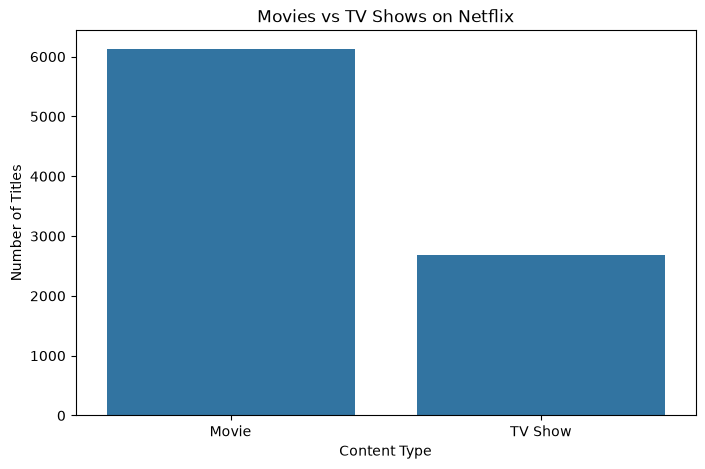

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="type")

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.show()


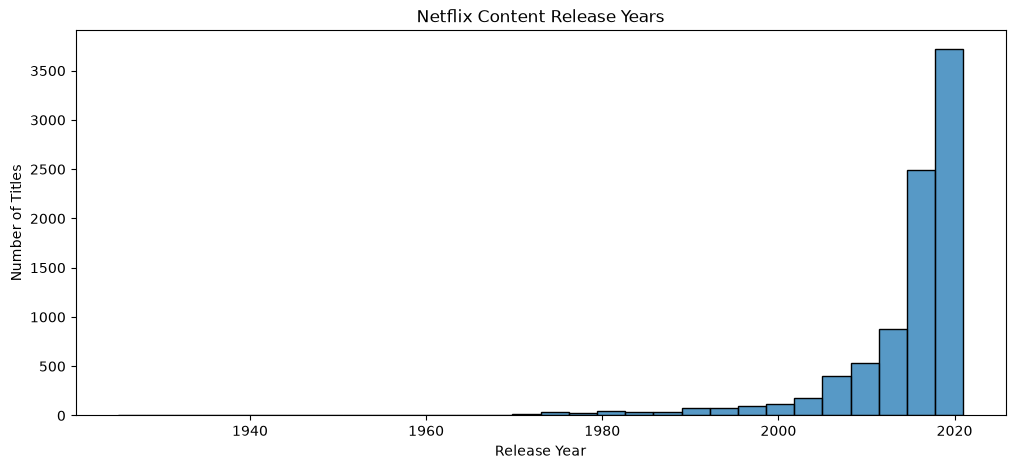

In [7]:

plt.figure(figsize=(12, 5))

sns.histplot(data=df, x="release_year", bins=30)

plt.title("Netflix Content Release Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()


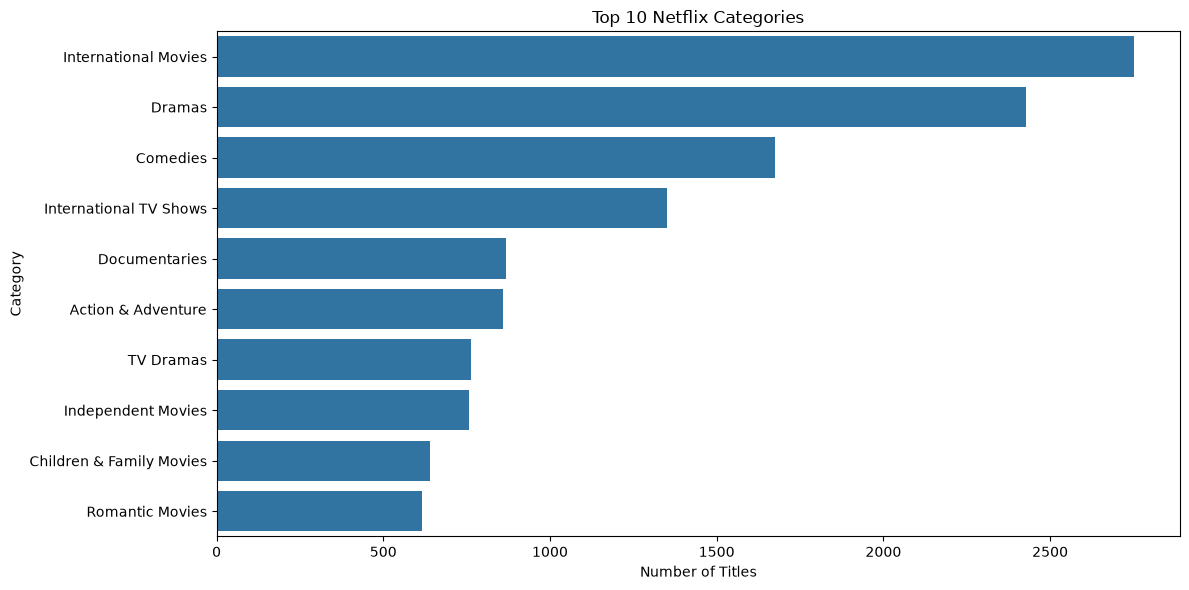

In [8]:

# Find the top 10 Netflix categories

categories = df["listed_in"].dropna().str.split(", ").explode()

top_10_categories = categories.value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index
)

plt.title("Top 10 Netflix Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Category")

plt.tight_layout()
plt.show()


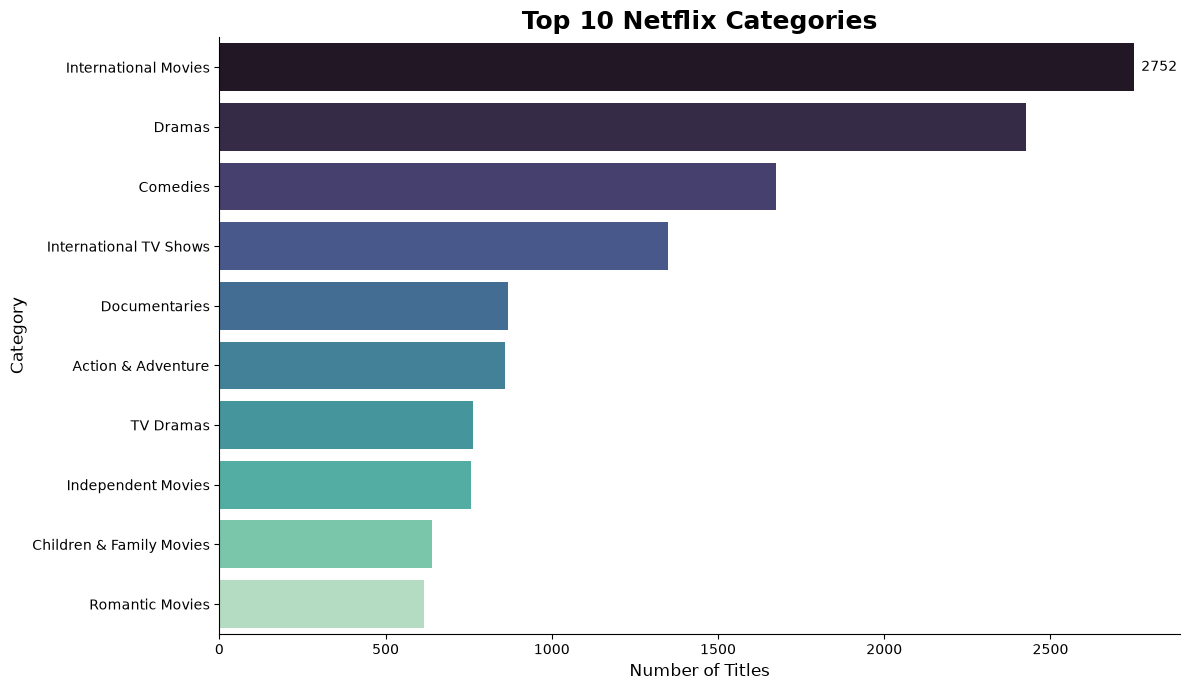

In [9]:

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index,
    hue=top_10_categories.index,
    palette="mako",
    legend=False
)

ax.bar_label(ax.containers[0], padding=5, fontsize=10)

plt.title("Top 10 Netflix Categories", fontsize=18, fontweight="bold")
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Category", fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()


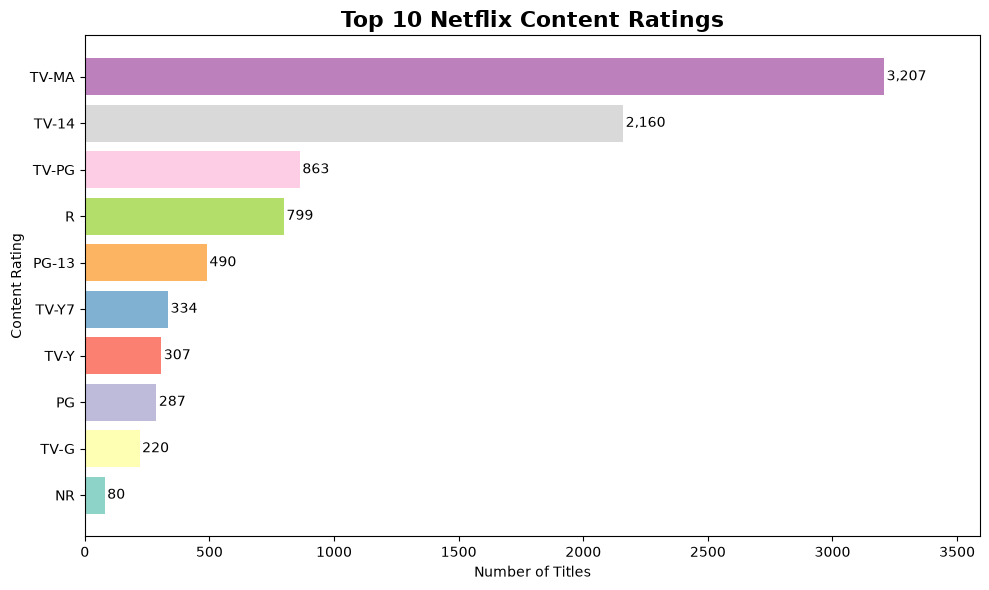

In [10]:

rating_counts = df["rating"].dropna().value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    rating_counts.index,
    rating_counts.values,
    color=plt.cm.Set3(range(len(rating_counts)))
)

for bar in bars:
    plt.text(
        bar.get_width() + 10,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center"
    )

plt.title("Top 10 Netflix Content Ratings", fontsize=16, fontweight="bold")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.xlim(0, rating_counts.max() * 1.12)
plt.tight_layout()
plt.show()


In [11]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

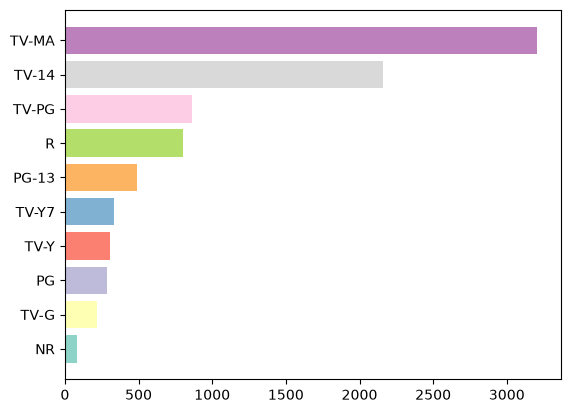

In [12]:
bars = plt.barh(
    rating_counts.index,
    rating_counts.values,
    color=plt.cm.Set3(range(len(rating_counts)))
)

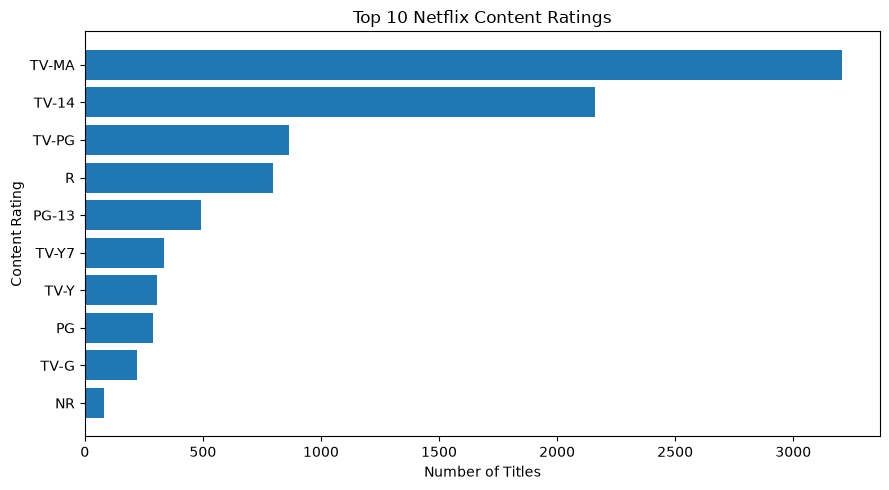

In [13]:

plt.close("all")

rating_counts = (
    df["rating"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    rating_counts.index,
    rating_counts.values
)

ax.set_title("Top 10 Netflix Content Ratings")
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Content Rating")

fig.tight_layout()
plt.show()


In [14]:

print(df["rating"].head(10))

print("\nMissing Ratings:")
print(df["rating"].isnull().sum())

print("\nTop Ratings:")
print(df["rating"].value_counts().head(10))


0    PG-13
1    TV-MA
2    TV-MA
3    TV-MA
4    TV-MA
5    TV-MA
6       PG
7    TV-MA
8    TV-14
9    PG-13
Name: rating, dtype: str

Missing Ratings:
4

Top Ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


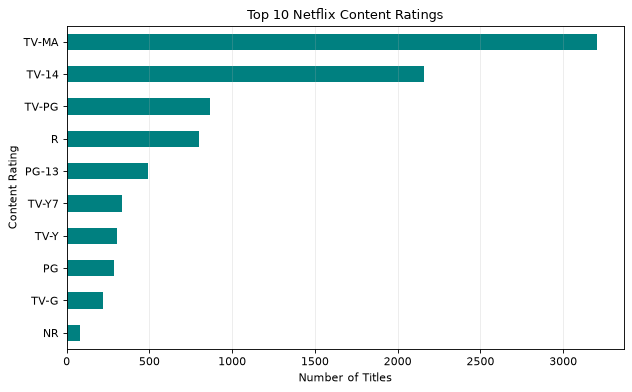

In [15]:

import matplotlib.pyplot as plt

plt.close("all")

rating_counts = (
    df["rating"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5), dpi=80)

rating_counts.plot(
    kind="barh",
    ax=ax,
    color="teal"
)

ax.set_title("Top 10 Netflix Content Ratings")
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Content Rating")

ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()


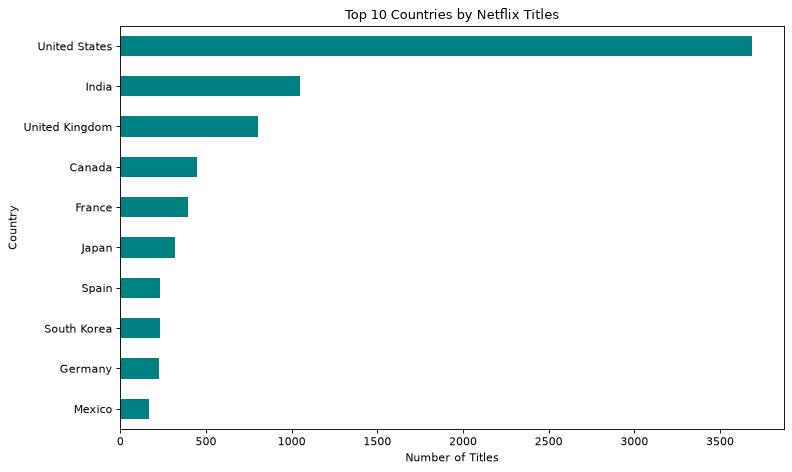

In [16]:

# Count titles by country
country_counts = (
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
    .sort_values()
)

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 6), dpi=80)

country_counts.plot(kind="barh", ax=ax, color="teal")

ax.set_title("Top 10 Countries by Netflix Titles")
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Country")

plt.tight_layout()
plt.show()


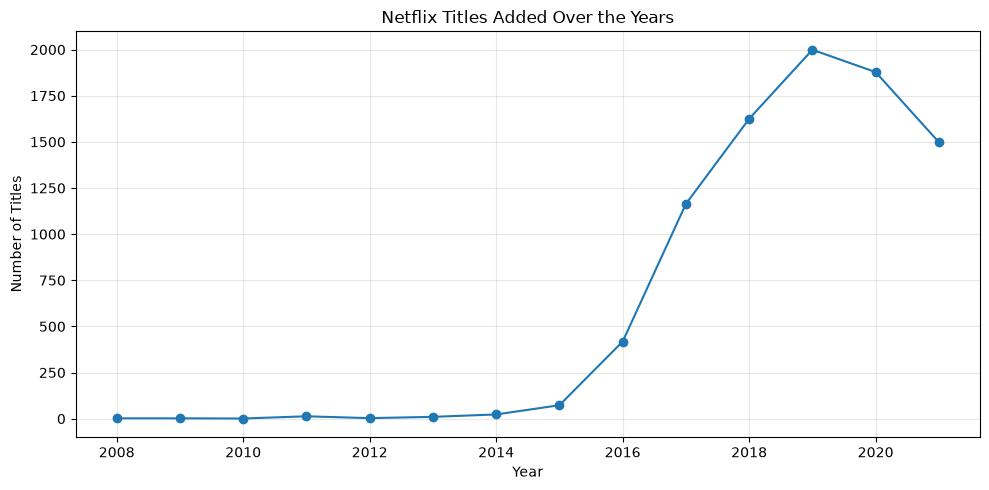

In [17]:

# Convert date_added into datetime format
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

# Extract the year and count titles added each year
year_counts = (
    df["date_added"]
    .dropna()
    .dt.year
    .value_counts()
    .sort_index()
)

# Create a line chart
plt.figure(figsize=(10, 5))

plt.plot(
    year_counts.index,
    year_counts.values,
    marker="o"
)

plt.title("Netflix Titles Added Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Count Movies and TV Shows
content_counts = df["type"].value_counts()

# Display the counts
print("Content Counts:")
print(content_counts)

# Calculate percentages
content_percent = (content_counts / len(df)) * 100

print("\nContent Percentage:")
print(content_percent.round(2))


Content Counts:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Content Percentage:
type
Movie      69.62
TV Show    30.38
Name: count, dtype: float64


In [19]:

# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)


Total Duplicate Rows: 0


In [20]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Show only columns that have missing values
missing_values = missing_values[missing_values > 0]

# Sort from highest to lowest
missing_values = missing_values.sort_values(ascending=False)

print("Columns with Missing Values:")
print(missing_values)


Columns with Missing Values:
director      2634
country        831
cast           825
date_added      98
rating           4
duration         3
dtype: int64


In [21]:

# Calculate missing values percentage
missing_percent = (df.isnull().sum() / len(df)) * 100

# Keep only columns with missing values
missing_percent = missing_percent[missing_percent > 0]

# Sort from highest to lowest
missing_percent = missing_percent.sort_values(ascending=False)

print("Missing Values Percentage:")
print(missing_percent.round(2))


Missing Values Percentage:
director      29.91
country        9.44
cast           9.37
date_added     1.11
rating         0.05
duration       0.03
dtype: float64


In [22]:

# Create a copy of the original dataset
df_clean = df.copy()

# Fill missing values in selected columns
columns_to_fill = [
    "director",
    "country",
    "cast",
    "rating",
    "duration"
]

for col in columns_to_fill:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Check remaining missing values
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())


Missing Values After Cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [23]:

# Save the cleaned dataset
df_clean.to_csv("netflix_titles_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)


Cleaned dataset saved successfully!
Original dataset shape: (8807, 12)
Cleaned dataset shape: (8807, 12)


In [24]:

# Separate Movie durations and TV Show seasons

movie_duration = pd.to_numeric(
    df_clean.loc[df_clean["type"] == "Movie", "duration"]
    .str.extract(r"(\d+)")[0],
    errors="coerce"
).dropna()

tv_seasons = pd.to_numeric(
    df_clean.loc[df_clean["type"] == "TV Show", "duration"]
    .str.extract(r"(\d+)")[0],
    errors="coerce"
).dropna()

# Analyze Movie durations
print("Movie Analysis")
print("Number of movies with duration data:", len(movie_duration))
print("Average movie duration:", round(movie_duration.mean(), 2), "minutes")
print("Median movie duration:", movie_duration.median(), "minutes")

# Analyze TV Show seasons
print("\nTV Shows Analysis")
print("Number of TV Shows with season data:", len(tv_seasons))
print("Median number of seasons:", tv_seasons.median())
print("Most common number of seasons:", tv_seasons.mode().iloc[0])


Movie Analysis
Number of movies with duration data: 6128
Average movie duration: 99.58 minutes
Median movie duration: 98.0 minutes

TV Shows Analysis
Number of TV Shows with season data: 2676
Median number of seasons: 1.0
Most common number of seasons: 1


# Findings


## Key Findings

### Movie Duration
- Movies with available duration data: 6,128
- Average movie duration: 99.58 minutes
- Median movie duration: 98 minutes

### TV Show Seasons
- TV Shows with available season data: 2,676
- Median number of seasons: 1
- Most common number of seasons: 1

### Conclusion
In this dataset, the average movie duration is approximately 100 minutes. For TV Shows, one season is both the median and the most common number of seasons.


In [25]:

# Create a temporary copy for this analysis
year_data = df_clean.copy()

# Convert date_added into datetime format
year_data["date_added"] = pd.to_datetime(
    year_data["date_added"],
    errors="coerce"
)

# Extract the year
year_data["year_added"] = year_data["date_added"].dt.year

# Count Movies and TV Shows added each year
year_type_counts = (
    year_data
    .dropna(subset=["year_added"])
    .groupby(["year_added", "type"])
    .size()
    .unstack(fill_value=0)
)

# Display the latest 10 years in the dataset
print(year_type_counts.tail(10))


type        Movie  TV Show
year_added                
2012.0          3        0
2013.0          6        4
2014.0         19        4
2015.0         56       17
2016.0        253      165
2017.0        839      325
2018.0       1237      388
2019.0       1424      575
2020.0       1284      594
2021.0        993      505


In [26]:

# Count total titles added each year
year_totals = year_type_counts.sum(axis=1)

# Find the year with the highest number of titles
peak_year = year_totals.idxmax()

# Display the findings
print("Year with the most titles added:", int(peak_year))
print("Total titles added in that year:", int(year_totals.loc[peak_year]))

print("\nBreakdown by content type:")
print(year_type_counts.loc[peak_year])


Year with the most titles added: 2019
Total titles added in that year: 1999

Breakdown by content type:
type
Movie      1424
TV Show     575
Name: 2019.0, dtype: int64


 # Key Finding


## Key Finding: Netflix Titles Added in 2019

- The highest number of titles in this dataset was added in 2019.
- A total of 1,999 titles were added in that year.
- Movies accounted for 1,424 titles (71.24%).
- TV Shows accounted for 575 titles (28.76%).

### Conclusion
In this dataset, Movies represented the larger share of titles added in 2019.


In [27]:

# Create a summary table of our analysis

summary = pd.DataFrame({
    "Metric": [
        "Total Titles",
        "Number of Movies",
        "Number of TV Shows",
        "Average Movie Duration (minutes)",
        "Median Movie Duration (minutes)",
        "Median TV Show Seasons",
        "Most Common TV Show Seasons",
        "Year with Most Titles Added",
        "Titles Added in Peak Year"
    ],

    "Value": [
        len(df_clean),
        int(content_counts.get("Movie", 0)),
        int(content_counts.get("TV Show", 0)),
        round(movie_duration.mean(), 2),
        round(movie_duration.median(), 2),
        tv_seasons.median(),
        tv_seasons.mode().iloc[0],
        int(peak_year),
        int(year_totals.loc[peak_year])
    ]
})

# Display the summary table
summary


,Metric,Value
0,Total Titles,8807.00
1,Number of Movies,6131.00
2,Number of TV Shows,2676.00
3,Average Movie Duration (minutes),99.58
4,Median Movie Duration (minutes),98.00
5,Median TV Show Seasons,1.00
6,Most Common TV Show Seasons,1.00
7,Year with Most Titles Added,2019.00
8,Titles Added in Peak Year,1999.00


In [28]:

summary.to_csv("netflix_analysis_summary.csv", index=False)

print("Analysis summary saved successfully!")


Analysis summary saved successfully!


In [29]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [30]:
# Load the cleaned dataset
df_clean = pd.read_csv("netflix_titles_cleaned.csv")

# Display the first 5 rows as a table
df_clean.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
